In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [12]:
# Parameters
beta_A = 1.0    # algae growth rate
C_A = 0.5       # shrimp-algae interaction rate
gamma_S = 0.3   # shrimp gain per algae eaten
C_S = 0.4       # bird-shrimp interaction rate
gamma_B = 0.3   # bird gain per shrimp eaten


def model(t, y, delta_B):
    S, A, B = y
    dS = gamma_S * C_A * S * A - C_S * S * B
    dA = beta_A * A - C_A * S * A
    dB = -delta_B * B + gamma_B * C_S * S * B
    return [dS, dA, dB]


def run(y0, delta_B, T):
    t = np.linspace(0, T, 3000)
    sol = solve_ivp(model, (0, T), y0, args=(delta_B,), t_eval=t,
                    method="LSODA", rtol=1e-9, atol=1e-12)
    return sol.t, sol.y

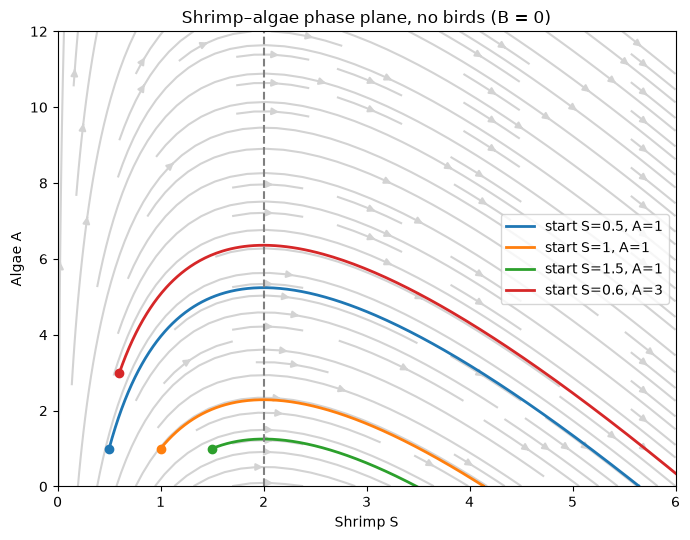

In [13]:
# Plot 1: shrimp vs algae with no birds (B = 0)
S_grid, A_grid = np.meshgrid(np.linspace(0.01, 6, 40), np.linspace(0.01, 12, 40))
dS_grid = gamma_S * C_A * S_grid * A_grid
dA_grid = beta_A * A_grid - C_A * S_grid * A_grid

plt.figure(figsize=(7, 5.5))
plt.streamplot(S_grid, A_grid, dS_grid, dA_grid, color="lightgray", density=1.1)

for S0, A0 in [(0.5, 1), (1, 1), (1.5, 1), (0.6, 3)]:
    t, y = run([S0, A0, 0.0], delta_B=0.5, T=40)   # delta_B unused when B = 0
    line, = plt.plot(y[0], y[1], linewidth=2, label=f"start S={S0}, A={A0}")
    plt.plot(S0, A0, "o", color=line.get_color())
    plt.legend()


plt.axvline(beta_A / C_A, color="gray", linestyle="--", label="algae nullcline S = β_A/C_A")
plt.xlim(0, 6)
plt.ylim(0, 12)
plt.xlabel("Shrimp S")
plt.ylabel("Algae A")
plt.title("Shrimp–algae phase plane, no birds (B = 0)")
plt.tight_layout()
plt.savefig("shrimp_algae_plane.png", dpi=300)

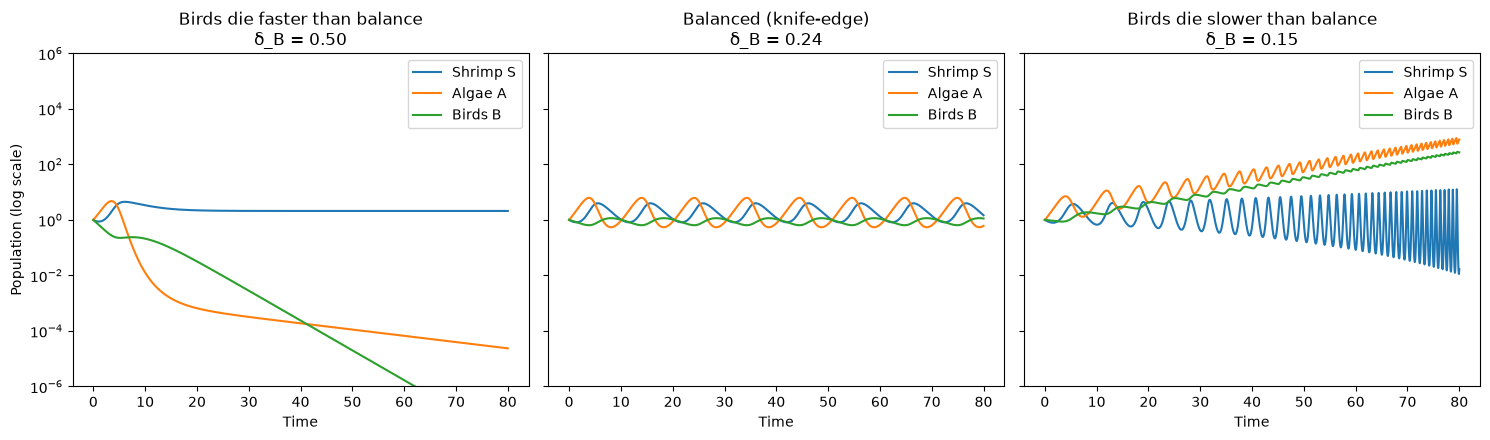

In [14]:
# Plot 2: time series for three bird death rates

balanced = gamma_B * C_S * beta_A / C_A   # = 0.24, the only value allowing cycles
cases = [("Birds die faster than balance", 0.50),
         ("Balanced (knife-edge)", balanced),
         ("Birds die slower than balance", 0.15)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, (name, delta_B) in zip(axes, cases):
    t, y = run([1.0, 1.0, 1.0], delta_B, T=80)
    ax.plot(t, y[0], label="Shrimp S")
    ax.plot(t, y[1], label="Algae A")
    ax.plot(t, y[2], label="Birds B")
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1e6)
    ax.set_title(f"{name}\nδ_B = {delta_B:.2f}")
    ax.set_xlabel("Time")
    ax.legend()
axes[0].set_ylabel("Population (log scale)")
plt.tight_layout()
plt.savefig("timeseries.png", dpi=300)

plt.show()